# Stage 5: Entanglement purification (DEJMPS)

**Question:** if a pair is too noisy to use, can two noisy pairs be combined into one better pair?

**Protocol (Deutsch et al., 1996).** A and B share two pairs. Each applies local rotations,
then a CNOT from its first qubit to its second (a *bilateral CNOT*). Both measure their second qubit in Z
and compare results over a classical channel. If the results agree, they keep the first pair, which is now better.
If not, both pairs are discarded.

The input states are general Bell-diagonal mixtures, built in PennyLane with a Pauli channel (`qml.QubitChannel`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qnet import physics as P, quantum as Q, plotstyle as S
S.apply()

In [2]:
import pennylane as qml
print(qml.draw(Q._purify_circuit)(np.array([0.85, .05, .05, .05]), np.array([0.85, .05, .05, .05])))
werner = lambda F: np.array([F, (1 - F) / 3, (1 - F) / 3, (1 - F) / 3])

0: ──H─╭●──RX(1.57)─────────────────────────────╭●────┤ ╭DensityMatrix
1: ────╰X──QubitChannel(M0,M1,M2,M3)──RX(-1.57)─│──╭●─┤ ├DensityMatrix
2: ──H─╭●──RX(1.57)─────────────────────────────╰X─│──┤ ├DensityMatrix
3: ────╰X──QubitChannel(M0,M1,M2,M3)──RX(-1.57)────╰X─┤ ╰DensityMatrix

M0 = 
[[0.92195445 0.        ]
 [0.         0.92195445]]
M1 = 
[[ 0.2236068+0.j  0.       +0.j]
 [ 0.       +0.j -0.2236068+0.j]]
M2 = 
[[0.       +0.j 0.2236068+0.j]
 [0.2236068+0.j 0.       +0.j]]
M3 = 
[[0.+0.j        0.-0.2236068j]
 [0.+0.2236068j 0.+0.j       ]]


## 1. One round: simulation against the textbook map

max |simulation - theory| = 2.220446049250313e-16


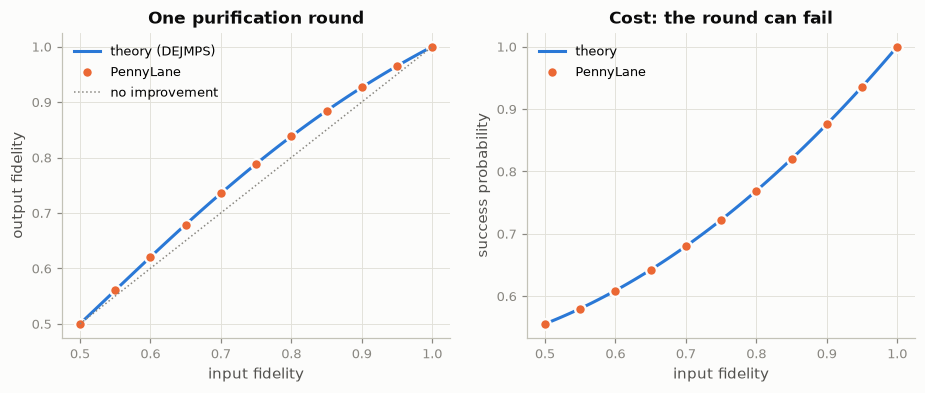

In [3]:
F_in = np.linspace(0.5, 1, 11)
sim = [Q.purify(werner(F)) for F in F_in]
F_out_sim = [s[0][0] for s in sim]; p_sim = [s[1] for s in sim]
th = [Q.dejmps_theory(werner(F)) for F in np.linspace(0.5, 1, 101)]
print("max |simulation - theory| =", max(abs(Q.purify(werner(F))[0][0] - Q.dejmps_theory(werner(F))[0][0]) for F in F_in))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
Fg = np.linspace(0.5, 1, 101)
ax[0].plot(Fg, [t[0][0] for t in th], label="theory (DEJMPS)")
ax[0].plot(F_in, F_out_sim, "o", label="PennyLane", ms=7, mec="#fcfcfb", mew=1.5)
ax[0].plot(Fg, Fg, color=S.THRESH, lw=1, ls=":", label="no improvement")
ax[0].set(xlabel="input fidelity", ylabel="output fidelity", title="One purification round")
ax[0].legend()
ax[1].plot(Fg, [t[1] for t in th], label="theory")
ax[1].plot(F_in, p_sim, "o", label="PennyLane", ms=7, mec="#fcfcfb", mew=1.5)
ax[1].set(xlabel="input fidelity", ylabel="success probability", title="Cost: the round can fail")
ax[1].legend()
S.save(fig, "05_one_round")

## 2. Repeated rounds (recurrence)

start 0.65: fidelities [0.65   0.6791 0.774  0.871  0.9299]; raw pairs used per output pair [ 1.   3.1 10.4 30.2 74. ]
start 0.75: fidelities [0.75   0.7885 0.9024 0.97   0.9899]; raw pairs used per output pair [ 1.   2.8  8.  19.1 40.3]
start 0.85: fidelities [0.85   0.8841 0.9716 0.996  0.9992]; raw pairs used per output pair [ 1.   2.4  6.1 12.8 25.8]


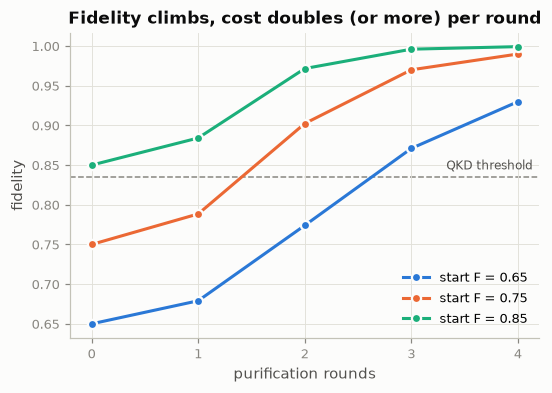

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for F0 in [0.65, 0.75, 0.85]:
    c, Fs, cost = werner(F0), [F0], [1]
    for r in range(4):
        c, p = Q.purify(c)
        Fs.append(c[0]); cost.append(cost[-1] * 2 / p)
    ax.plot(range(5), Fs, "-o", label=f"start F = {F0}", mec="#fcfcfb", mew=1.5)
    print(f"start {F0}: fidelities {np.round(Fs, 4)}; raw pairs used per output pair {np.round(cost, 1)}")
S.threshold(ax, 0.835, "QKD threshold")
ax.set(xlabel="purification rounds", ylabel="fidelity", xticks=range(5), title="Fidelity climbs, cost doubles (or more) per round")
ax.legend(loc="lower right")
S.save(fig, "05_rounds")

## 3. Application: rescue a 3-link chain

From Stage 2: three links of F = 0.93 swap to an end-to-end pair below the QKD threshold.
Purify the end-to-end pairs and check whether they become usable.

In [5]:
chain3 = Q.make_chain_circuit(3, "dm")
w1 = (4 * 0.93 - 1) / 3
c = Q.bell_coefficients(chain3(w1))
Qz = lambda c: c[1] + c[2]          # Z errors come from the psi components
Qx = lambda c: c[1] + c[3]          # X errors come from psi- and phi-
cost = 1
print(f"after swapping: F = {c[0]:.4f}, QBER_Z = {Qz(c)*100:.1f}%, QBER_X = {Qx(c)*100:.1f}%, "
      f"key fraction = {Q.bbm92_key_fraction(Qz(c), Qx(c)):.3f}")
for r in range(1, 3):
    c, p = Q.purify(c); cost *= 2 / p
    print(f"after {r} round(s): F = {c[0]:.4f}, QBER_Z = {Qz(c)*100:.1f}%, QBER_X = {Qx(c)*100:.1f}%, "
          f"key fraction = {Q.bbm92_key_fraction(Qz(c), Qx(c)):.3f}, raw pairs per final pair = {cost:.1f}")

after swapping: F = 0.8090, QBER_Z = 12.7%, QBER_X = 12.7%, key fraction = 0.000
after 1 round(s): F = 0.8467, QBER_Z = 2.1%, QBER_X = 14.3%, key fraction = 0.247, raw pairs per final pair = 2.6
after 2 round(s): F = 0.9496, QBER_Z = 2.7%, QBER_X = 2.7%, key fraction = 0.623, raw pairs per final pair = 6.8


## Takeaways

* The PennyLane circuit reproduces the DEJMPS map exactly, including success probability, across repeated rounds.
* Purification turns an unusable 3-hop pair into a usable one, at the cost of several raw pairs and extra classical messages.
  Every round needs a classical exchange, so memories wait longer (Stage 3). Rate, quality and classical latency trade off against each other.